In [1]:
%matplotlib inline
import itertools
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import active_subspaces as ac

SEED = 241
np.set_printoptions(precision=4, suppress=True, linewidth=110)
T_START = time.time()
# OLS and QPHD on a box of discrete levels are outside their textbook assumptions (discussed in the text)
warnings.simplefilter('ignore', ac.ValidityWarning)
warnings.filterwarnings('ignore', message='The figure layout has changed')

# Active subspaces of the energy use intensity of a synthetic stock of Irish semi-detached houses (EnergyPlus)

Stored data from

U. Ali, S. Bano, M. H. Shamsi, D. Sood, C. Hoare, W. Zuo, N. Hewitt and J. O'Donnell, *Urban residential
building stock synthetic datasets for building energy performance analysis*, Data in Brief 53:110241, 2024.
[doi:10.1016/j.dib.2024.110241](https://doi.org/10.1016/j.dib.2024.110241)

a School of Mechanical and Materials Engineering and UCD Energy Institute, UCD, Dublin, Ireland; b School of
Architecture and The Built Environment, Ulster University, Belfast, UK; c Pennsylvania State University,
University Park, PA, USA; d Flemish Institute for Technological Research (VITO), Boeretang Mol, Belgium.
(Ali a; Bano a; Shamsi d; Sood a; Hoare a; Zuo c; Hewitt b; O'Donnell a.)

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

Ali et al. simulated the annual energy use of about one million Irish dwellings with jEPlus and EnergyPlus and
deposited the inputs and the energy use intensity (EUI); this notebook takes the 49,298 runs of one cell
(semi-detached, historical weather, no renewables), in which each of the 15 numeric inputs takes between 4 and
34 discrete levels and no run has an EUI of 650 kWh/(m² yr) or more. Gradients estimated as the slopes of
least-squares linear fits to the 60 nearest rows (wide windows in 15 dimensions) give
$\lambda_1/\lambda_2 = 39.65$ and one active variable led by the HVAC efficiency (−0.807) and the hot-water
use (+0.422), whose cubic fit has leave-one-out $R^2$ 0.8286; the eigenvalues after the first are dominated by
the variance of those local fits, but a weaker smooth structure (the directions $w_3$ and $w_4$) raises the
$R^2$ to 0.8658, close to the 0.8664 of a quadratic in all 15 inputs. A version of the cell rebuilt without the
cutoff at 650 turns the leading direction only slightly ($|\cos|$ 0.9934 for the linear fit) but has a leading
eigenvalue 4.57 times larger, and the simulated space heating, through which the envelope inputs act, is not
monotone in the wall and roof U-values, which behave like labels of construction templates rather than
physical conductances.

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after
the $n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$
shows. Here $\rho$ is the empirical distribution of the 49,298 stored rows, so $\mathbf{C}$ is the average of
$\nabla f\, \nabla f^\top$ over the rows; the Table 4 box only sets the scaling of the inputs (below). No
gradients exist, so $\mathbf{C}$ is estimated from the stored values: the local linear estimator fits a linear
function to the 60 nearest rows around each row and averages the outer products of the fitted slopes; the
global quadratic estimator fits one least-squares quadratic to all rows and averages the outer products of its
gradient over the rows; the linear estimator (OLS) fits $f \approx c + \mathbf{u}^\top\mathbf{x}$ and takes
$w_1 = \mathbf{u}/\|\mathbf{u}\|$ (one direction only). The library's QPHD estimator, shown as a check,
averages the quadratic's gradient over the uniform box instead of the rows
($\mathbf{g}\mathbf{g}^\top + \mathbf{H}\boldsymbol{\Sigma}\mathbf{H}$, with $\mathbf{g}$ the gradient at the
box centre and $\boldsymbol{\Sigma} = \mathbf{I}/3$). See P. G. Constantine, *Active Subspaces: Emerging
Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015,
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Simulator.** jEPlus drives EnergyPlus annual simulations of four Irish residential archetypes (terraced,
detached, semi-detached, bungalow; geometry in Fig. 2, p. 7) with DesignBuilder construction templates, which
represent the thickness, conductivity, density and heat capacity of each construction through its U-value
(Sect. 4.3, p. 8). Weather: the Dublin EnergyPlus weather file, historical and projected for 2030
(Meteonorm), p. 7. The paper states "This study uses the LHS method to generate a sample of 1 million
buildings" (p. 9) and gives the ranges of the inputs (Table 4, p. 8), but no distributions, no EnergyPlus or
jEPlus version, and no run time; the archetype models are not published, so no new runs can be made.

**This data set's cell.** The rows with building type semi-detached, historical weather and no renewables,
which fixes the four categorical inputs of Table 4 (building type, location Dublin, weather, renewables) and
leaves the 15 numeric inputs below. The choice of cell is this data set's; the other cells of the deposit can
be extracted with `convert_data.py`. The design of these rows is described here as a subset of the deposited
design: in the data every input takes a few discrete levels, so whether the rows form a Latin hypercube cannot
be checked.

**Quantity of interest.** The energy use intensity, a building's "annual primary energy usage per square meter
of total floor space, expressed in kWh/(m²·year)" (p. 8). The stored values satisfy (cell below; the formula
is read off the stored columns, the paper gives the conversion factors only by their means, Table 3, p. 5)

$$
\mathrm{EUI} = \frac{p_H\, c_H\, Q_{\mathrm{heat}} + p_E\, E_{\mathrm{el}}}{A}, \qquad
c_H = \mathrm{round}(1.084/\eta,\ 3), \qquad
p_H = \begin{cases} 1.1, & \eta \le 0.9 \\ 2.08, & \eta \ge 2 \end{cases}, \qquad p_E = 2.08,
$$

with $\eta$ the HVAC efficiency, $Q_{\mathrm{heat}}$ the heating usage (space heating plus water heating,
kWh/yr), $E_{\mathrm{el}}$ the lighting plus equipment electricity (kWh/yr; no photovoltaics in this cell) and
$A$ the floor area (m²). The two branches of $p_H$ read like the primary-energy factors of gas and
electricity, so $\eta \le 0.9$ looks like a boiler efficiency and $\eta \ge 2$ like a heat-pump COP (Table 4
says "HVAC Efficiency/COP"); this reading is an inference. A secondary output, the annual space heating
energy, is analysed further below.

**Inputs** ($m = 15$). Ranges from Table 4 (p. 8); units from Table 2 (p. 4), as Table 4 prints none; the
number of levels is counted in the data (cell below).

| column | Table 4 name | units | Table 4 range | levels in this cell |
|---|---|---|---|---|
| `U_floor` | Floor U-value | W/(m² K) | [0.15, 1.6] | 28 |
| `U_door` | Door U-value | W/(m² K) | [0.81, 5.7] | 10 |
| `U_roof` | Roof U-value | W/(m² K) | [0.07, 2.28] | 21 |
| `U_window` | Window U-value | W/(m² K) | [0.73, 5.75] | 34 |
| `U_wall` | Wall U-value | W/(m² K) | [0.09, 2.4] | 25 |
| `HVAC_efficiency` | HVAC Efficiency/COP | 1 (Table 2 prints "%") | [0.3, 4.5] | 20 |
| `DHW_use` | Domestic Hot Water | L/(m² day) | [0.5, 3.5] | 4 |
| `orientation` | Orientation | deg | [0, 315] | 8 |
| `lighting_density` | Lighting Density | W/m² | [1, 9] | 5 |
| `occupancy` | Occupancy | persons | [1, 6] | 6 |
| `equipment_density` | Equipment Density | W/m² | [1, 21] | 5 |
| `heating_setpoint` | Heating Setpoint | °C | [18, 23] | 6 |
| `heating_setback` | Heating Setback | °C | [10, 14] | 5 |
| `air_change_rate` | Air Change Per Hour | 1/h | [0.35, 3] | 7 |
| `window_to_wall_ratio` | Window-to-Wall Ratio | % | [0, 70] | 4 |

**Scaling.** Each input is mapped linearly from its Table 4 range to $[-1, 1]$, and gradients and eigenvectors
are in these coordinates. This is this data set's choice (the paper states no distributions). The box sets only
the scaling: the averages that define $\mathbf{C}$ are over the rows, whose distribution is far from uniform
on the box for some inputs (the floor U-value has 27 of its 28 levels in [0.15, 0.84] W/(m² K), printed below,
and the HVAC efficiency has no level between 0.9 and 2). A check further below repeats the linear fit with
each input mapped through its empirical CDF instead.

## Load the data

`building_inputs.csv` holds the 15 inputs in physical units; `building_outputs.csv` holds, row for row, the
1-based row number in the deposited table (`source_row`) and the 12 numeric outputs, among them `EUI`
(kWh/(m² yr)) and `space_heating_energy` (kWh/yr). `convert_data.py` extracts both from the deposited archive
(Mendeley Data, [doi:10.17632/m6vv9k9gcd.1](https://doi.org/10.17632/m6vv9k9gcd.1)) without changing a value.

In [2]:
def read_csv(name):
    """Values, column names and units of one of this data set's CSV files."""
    with open(name) as fh:
        fh.readline()
        cols = fh.readline()[2:].strip().split(',')
    names = [c.split(' [')[0] for c in cols]
    units = [c.split(' [')[1].rstrip(']') for c in cols]
    return np.loadtxt(name, delimiter=','), names, units


X, names, units = read_csv('building_inputs.csv')
Y, onames, ounits = read_csv('building_outputs.csv')
out = {n: Y[:, j] for j, n in enumerate(onames)}
f = out['EUI']                    # energy use intensity, kWh/(m2 yr)
SH = out['space_heating_energy']  # annual space heating energy, kWh/yr
eta = X[:, names.index('HVAC_efficiency')]
M, m = X.shape
print('inputs', X.shape, ' outputs', Y.shape)
print('columns of the inputs file:', ', '.join(names))

inputs (49298, 15)  outputs (49298, 13)
columns of the inputs file: U_floor, U_door, U_roof, U_window, U_wall, HVAC_efficiency, DHW_use, orientation, lighting_density, occupancy, equipment_density, heating_setpoint, heating_setback, air_change_rate, window_to_wall_ratio


The next cell checks that every row lies in the Table 4 box, counts the levels of each input and the rows
per level, and finds the largest correlation between two inputs.

In [3]:
# Table 4 (p. 8) bounds, in the column order of building_inputs.csv
lower = np.array([0.15, 0.81, 0.07, 0.73, 0.09, 0.3, 0.5, 0.0, 1.0, 1.0, 1.0, 18.0, 10.0, 0.35, 0.0])
upper = np.array([1.6, 5.7, 2.28, 5.75, 2.4, 4.5, 3.5, 315.0, 9.0, 6.0, 21.0, 23.0, 14.0, 3.0, 70.0])
space = ac.Uniform(lower, upper, names=names)
print('every row inside the Table 4 box:', bool(np.all((X >= lower) & (X <= upper))))
for j, n in enumerate(names):
    lev, cnt = np.unique(X[:, j], return_counts=True)
    print(f'{n:22s} {len(lev):3d} levels, {lev.min():g} to {lev.max():g} {units[j]:9s}'
          f' rows per level {cnt.min()} to {cnt.max()}')
R = np.corrcoef(X.T)
np.fill_diagonal(R, 0.0)
i, j = np.unravel_index(np.abs(R).argmax(), R.shape)
print(f'largest |correlation| between two inputs: {R[i, j]:.3f} ({names[i]}, {names[j]})')

every row inside the Table 4 box: True
U_floor                 28 levels, 0.15 to 1.6 W/m2K     rows per level 1659 to 1861
U_door                  10 levels, 0.81 to 5.7 W/m2K     rows per level 4872 to 5009
U_roof                  21 levels, 0.07 to 2.28 W/m2K     rows per level 2238 to 2490
U_window                34 levels, 0.73 to 5.75 W/m2K     rows per level 1366 to 1527
U_wall                  25 levels, 0.1 to 2.4 W/m2K     rows per level 1805 to 2073
HVAC_efficiency         20 levels, 0.3 to 4.4 1         rows per level 469 to 2931
DHW_use                  4 levels, 0.5 to 3.5 L/m2/day  rows per level 10851 to 13631
orientation              8 levels, 0 to 315 deg       rows per level 6102 to 6231
lighting_density         5 levels, 1 to 9 W/m2      rows per level 9750 to 9936
occupancy                6 levels, 1 to 6 persons   rows per level 7996 to 8525
equipment_density        5 levels, 1 to 21 W/m2      rows per level 9716 to 10057
heating_setpoint         6 levels, 18 to 2

Every row lies in the Table 4 box. Each input takes between 4 (`DHW_use`, `window_to_wall_ratio`) and 34
(`U_window`) levels; the rows are spread nearly evenly over the levels of every input except
`HVAC_efficiency` (469 to 2931 rows per level, explained below), and the largest correlation between two
inputs is 0.141 (`HVAC_efficiency`, `DHW_use`). The next cell checks the EUI formula of the model section
against the stored columns.

In [4]:
A = out['floor_area']
rebuilt = (out['heating_primary_factor'] * out['heating_conversion_factor'] * out['heating_usage']
           + out['electricity_primary_factor'] * out['electricity_energy']) / A
print(f'max |EUI - rebuilt EUI| = {np.abs(f - rebuilt).max():.1e} kWh/(m2 yr)')
cH = np.round(1.084 / eta, 3)
print(f'max |heating_conversion_factor - round(1.084/eta, 3)| = '
      f'{np.abs(out["heating_conversion_factor"] - cH).max():.1e}')
print('heating_primary_factor for eta <= 0.9:', np.unique(out['heating_primary_factor'][eta < 1]),
      ' for eta >= 2:', np.unique(out['heating_primary_factor'][eta > 1]))
print('floor area', np.unique(A), 'm2;  PV energy', np.unique(out['pv_energy']),
      ';  electricity primary factor', np.unique(out['electricity_primary_factor']))
d1 = out['heating_usage'] - out['water_systems_energy'] - SH
d2 = out['electricity_energy'] - out['lighting_energy'] - out['equipment_energy']
print(f'max |heating_usage - water_systems - space_heating| = {np.abs(d1).max():.3f} kWh/yr')
print(f'max |electricity - lighting - equipment| = {np.abs(d2).max():.3f} kWh/yr')
for q in ['water_systems_energy', 'lighting_energy', 'equipment_energy']:
    print(f'{q}: {np.unique(out[q]).size} distinct values')

max |EUI - rebuilt EUI| = 2.3e-13 kWh/(m2 yr)
max |heating_conversion_factor - round(1.084/eta, 3)| = 0.0e+00
heating_primary_factor for eta <= 0.9: [1.1]  for eta >= 2: [2.08]
floor area [107.69] m2;  PV energy [0.] ;  electricity primary factor [2.08]
max |heating_usage - water_systems - space_heating| = 0.010 kWh/yr
max |electricity - lighting - equipment| = 0.008 kWh/yr
water_systems_energy: 4 distinct values
lighting_energy: 5 distinct values
equipment_energy: 5 distinct values


The stored EUI equals the formula to rounding (of order $10^{-13}$ kWh/(m² yr) on values of a few hundred), the heating conversion factor agrees with
round(1.084/η, 3) in every row, and $p_H$ takes 1.1 for every $\eta \le 0.9$ and 2.08 for every $\eta \ge 2$.
The floor area is 107.69 m² in every row and the photovoltaic energy is zero. The heating usage is space plus
water heating, and the electricity is lighting plus equipment, to 0.010 and 0.008 kWh/yr (the two-decimal
rounding of the stored energies). The water-heating, lighting and equipment energies take only 4, 5 and 5
values, one per level of `DHW_use`, `lighting_density` and `equipment_density`; so the EUI is a known
function of $\eta$, these three inputs and one simulated output, the space heating, through which all the
envelope, ventilation and schedule inputs act.

In [5]:
lev, cnt = np.unique(eta, return_counts=True)
hp_mean = cnt[lev >= 2].mean()
print('rows per HVAC_efficiency level:', ', '.join(f'{v:g}: {c}' for v, c in zip(lev, cnt)))
print(f'mean rows per heat-pump level (eta >= 2): {hp_mean:.0f}; at eta = 0.3: {cnt[0]}')
expected = len(lev) * hp_mean
print(f'rows if every level had that mean: {expected:.0f}; rows present: {M} '
      f'(fraction missing {1 - M / expected:.3f})')
print(f'EUI: min {f.min():.2f}, max {f.max():.2f}, mean {f.mean():.2f}, sd {f.std(ddof=1):.2f}; '
      f'rows with EUI in [625, 650): {np.sum(f >= 625)}, in [600, 625): {np.sum((f >= 600) & (f < 625))}')
print('mean space heating (kWh/yr) by HVAC_efficiency:',
      ', '.join(f'{v:g}: {SH[eta == v].mean():.0f}' for v in lev[[0, 3, 6, 7, 13, 19]]))

rows per HVAC_efficiency level: 0.3: 469, 0.4: 855, 0.5: 1324, 0.6: 1785, 0.7: 2209, 0.8: 2560, 0.9: 2737, 2: 2852, 2.2: 2931, 2.4: 2926, 2.6: 2881, 2.8: 2862, 3: 2868, 3.2: 2906, 3.4: 2858, 3.6: 2850, 3.8: 2880, 4: 2855, 4.2: 2887, 4.4: 2803
mean rows per heat-pump level (eta >= 2): 2874; at eta = 0.3: 469
rows if every level had that mean: 57475; rows present: 49298 (fraction missing 0.142)
EUI: min 42.82, max 649.97, mean 315.91, sd 125.51; rows with EUI in [625, 650): 684, in [600, 625): 714
mean space heating (kWh/yr) by HVAC_efficiency: 0.3: 6234, 0.6: 9872, 0.9: 11924, 2: 12731, 3.2: 12485, 4.4: 12883


**Missing high-EUI runs.** The heat-pump levels ($\eta \ge 2$) hold 2874 rows each on average, but
$\eta = 0.3$ holds 469. Had every level the heat-pump mean, the cell would have 57475 rows; it has 49298, a
fraction 0.142 missing. The EUI reaches 649.97 kWh/(m² yr), and its histogram does not taper towards that
value (684 rows in [625, 650) against 714 in [600, 625)): the runs with EUI ≥ 650 are absent. The lowest
heat-pump levels hold a few rows near the cutoff too (counted in the section on the cutoff below), so the levels
$\eta$ = 2 and 2.2 may be slightly thinned and the estimate of 57475 slightly low. The paper's
Table 3 (p. 5) prints a maximum EUI of 650 and does not mention a cutoff. Because the EUI grows like $1/\eta$,
the cutoff removes mostly low-efficiency runs, and among them those with high space heating: the mean space
heating is 6234 kWh/yr at $\eta = 0.3$, 9872 at 0.6 and 11924 at 0.9, against 12485–12883 for the heat-pump
levels shown. The space heating does not depend on $\eta$ in the formula, so this trend is the cutoff's
doing. A section further below rebuilds the cell without the cutoff and tests this reading. Everything below
describes the EUI on the set where it is below 650, and the inputs are not independent there (the 0.141
correlation of $\eta$ and `DHW_use` is the same effect).

U_wall    mean space heating at lowest level 8871, at highest 8596, range of level means 8596 to 19842 kWh/yr (at 2.4 and 1.95)
U_roof    mean space heating at lowest level 12037, at highest 12374, range of level means 8712 to 14874 kWh/yr (at 1.14 and 0.1)
U_window  mean space heating at lowest level 10237, at highest 14623, range of level means 10237 to 14972 kWh/yr (at 0.73 and 4.95)
U_floor   mean space heating at lowest level 12470, at highest 12507, range of level means 11450 to 12691 kWh/yr (at 0.38 and 0.16)


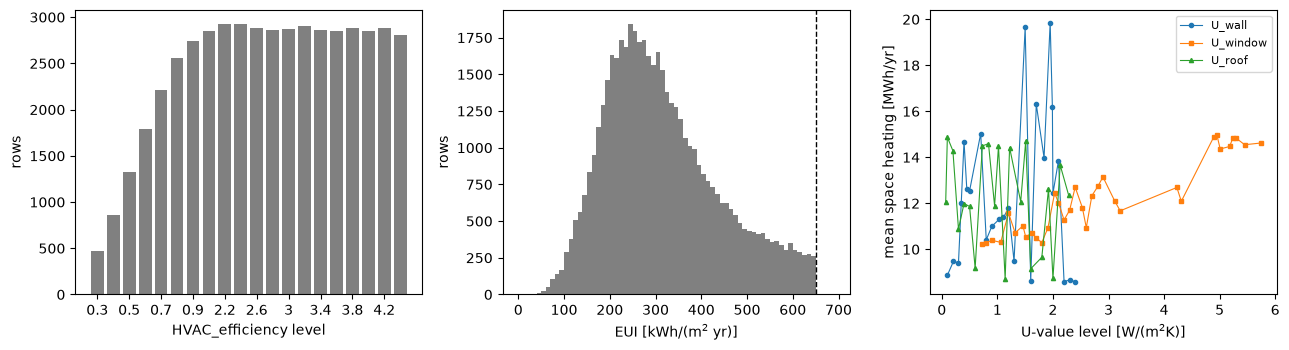

In [6]:
def level_means(j, y):
    lev = np.unique(X[:, j])
    return lev, np.array([y[X[:, j] == v].mean() for v in lev])


fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(np.arange(len(lev)), cnt, color='0.5')
ax[0].set_xticks(np.arange(len(lev))[::2], [f'{v:g}' for v in lev[::2]])
ax[0].set_xlabel('HVAC_efficiency level'); ax[0].set_ylabel('rows')
ax[1].hist(f, bins=np.arange(0, 700, 10), color='0.5')
ax[1].axvline(650, color='k', ls='--', lw=1)
ax[1].set_xlabel('EUI [kWh/(m$^2$ yr)]'); ax[1].set_ylabel('rows')
for n, mk in [('U_wall', 'o-'), ('U_window', 's-'), ('U_roof', '^-')]:
    lv, mu = level_means(names.index(n), SH)
    ax[2].plot(lv, mu / 1e3, mk, ms=3, lw=0.8, label=n)
ax[2].set_xlabel('U-value level [W/(m$^2$K)]'); ax[2].set_ylabel('mean space heating [MWh/yr]')
ax[2].legend(fontsize=8)
fig.tight_layout()
for n in ['U_wall', 'U_roof', 'U_window', 'U_floor']:
    lv, mu = level_means(names.index(n), SH)
    print(f'{n:9s} mean space heating at lowest level {mu[0]:.0f}, at highest {mu[-1]:.0f}, '
          f'range of level means {mu.min():.0f} to {mu.max():.0f} kWh/yr '
          f'(at {lv[mu.argmin()]:g} and {lv[mu.argmax()]:g})')
plt.close(fig)
fig

Left: rows per $\eta$ level. Middle: the EUI histogram, cut at 650 (dashed). Right: the mean space heating at
each level of three U-values. The wall U-value is far from monotone: the mean space heating is 8871 kWh/yr
at its lowest level and 8596 at its highest (2.4 W/(m² K)), while the level means range from 8596 to 19842
(the maximum at 1.95). The roof behaves the same way (level means 8712 to 14874, the maximum at its 0.1 level
and the minimum at 1.14); the window U-value is closer to increasing (10237 at 0.73 to 14972 at 4.95), and
the floor U-value matters little (level means 11450 to 12691). The paper says that the templates represent
the thickness, conductivity, density and heat capacity of the building materials through U-values (p. 8); in
these data the U-value columns act instead like labels of templates whose thermal effect is not ordered by the
label (why is not stated). No smooth function of these inputs can follow such
jumps, and they will show up as unexplained variance and as local roughness in the estimates below.

## Estimate the active subspace

**Estimator.** No gradients are available (EnergyPlus gives none and no runs can be made). The main estimator
is local linear: at every row, a linear function is fitted by least squares to the $p$ nearest distinct rows in
the normalized coordinates, and its slope is taken as the gradient estimate. With $M = 49298$ rows in
$m = 15$ dimensions the rows are far apart (the third cell below measures the neighbourhoods), so these slopes
are averages of the EUI's variation over wide windows, an outer-product-of-gradients estimate rather than
local derivatives. Because each input takes only a few levels, small neighbourhoods may not span all 15
directions; the first cell tries $p = 25$ at every tenth row and reports how many local systems are
rank-deficient, and the second uses $p = 60$ at all rows. The eigenvalues come with 200 bootstrap replicates
(seed `SEED`); they resample the rows of fitted slopes and do not refit the neighbourhoods, so their intervals
leave out the variance of the local fits, which the third cell estimates. The signs of $w_1$ to $w_4$ follow
the rule that $w_k^\top \mathbf{x}$ has positive sample covariance with the EUI (the paper has no
active-subspace figures to match). The fourth cell checks the result with the global quadratic (its number of
coefficients is printed), the library QPHD and OLS.

In [7]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    ac.local_linear_gradients(X=X, f=f, space=space, p=25, centers=np.arange(0, M, 10))
msgs = [str(w.message) for w in caught if issubclass(w.category, ac.AccuracyWarning)]
print('p = 25, every tenth row:', msgs[0] if msgs else 'no rank-deficient local systems')

p = 25, every tenth row: local_linear_gradients: 24 of 4930 local systems are rank-deficient; minimum-norm solutions used [accuracy.rank_deficient]


In [8]:
t = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    gll = ac.local_linear_gradients(X=X, f=f, space=space, p=60)
msgs = [str(w.message) for w in caught if issubclass(w.category, ac.AccuracyWarning)]
print(f'local linear gradients, p = {gll.p}, at {gll.grads.shape[0]} rows: {time.time() - t:.0f} s;',
      msgs[0] if msgs else 'no rank-deficient local systems')
sub = ac.active_subspace(grads=gll, space=space, nboot=200, bootstrap_vectors=4, rng=SEED)
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=4)
lam = sub.eigenvalues
ci = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
print('eigenvalues 1-8:', lam[:8].round(1))
print('95% bootstrap intervals of eigenvalues 1-4:', [f'[{a:.1f}, {b:.1f}]' for a, b in ci.T[:4]])
print('ratios lambda_k/lambda_k+1, k = 1-6:', (lam[:6] / lam[1:7]).round(2))
dist = sub.bootstrap_distances
print('subspace distance, median (95th percentile) for k = 1-4:',
      ', '.join(f'{np.median(dist[:, k]):.3f} ({np.percentile(dist[:, k], 95):.3f})' for k in range(4)))
print('left-out eigenvalue share for n = 1, 2, 3:', np.array([lam[k:].sum() / lam.sum() for k in (1, 2, 3)]).round(3))
print('dimension from the default eigenvalue-gap rule:', sub.n)

local linear gradients, p = 60, at 49298 rows: 121 s; no rank-deficient local systems


eigenvalues 1-8: [40537.7  1022.4   876.2   748.4   594.5   515.4   484.5   405.2]
95% bootstrap intervals of eigenvalues 1-4: ['[40346.2, 40750.0]', '[996.3, 1045.0]', '[860.8, 891.5]', '[730.6, 763.5]']
ratios lambda_k/lambda_k+1, k = 1-6: [39.65  1.17  1.17  1.26  1.15  1.06]
subspace distance, median (95th percentile) for k = 1-4: 0.002 (0.003), 0.039 (0.079), 0.041 (0.071), 0.039 (0.060)
left-out eigenvalue share for n = 1, 2, 3: [0.149 0.128 0.109]
dimension from the default eigenvalue-gap rule: 1


In [9]:
# The neighbourhoods of the local fits, rebuilt with a k-d tree. No row of X is repeated, so the 60
# nearest rows are the 60 nearest distinct rows used above.
t = time.time()
Xn = space.to_normalized(X)
print('distinct rows:', np.unique(Xn, axis=0).shape[0], 'of', M)
dnn, nbr = cKDTree(Xn).query(Xn, k=gll.p)
r60 = dnn[:, -1]
print(f'nearest-neighbour distance: median {np.median(dnn[:, 1]):.3f}; radius of the {gll.p} nearest rows: '
      f'median {np.median(r60):.2f} (5th-95th percentile {np.percentile(r60, 5):.2f}-{np.percentile(r60, 95):.2f});'
      f' the box has side 2')
spread = np.median(np.ptp(Xn[nbr], axis=1), axis=0)
print('median range of each input within a neighbourhood (normalized; full range 2):')
print('  ' + ', '.join(f'{names[k]} {spread[k]:.2f}' for k in range(m)))
e_nb = eta[nbr]
print(f'HVAC_efficiency within a neighbourhood: median range {np.median(np.ptp(e_nb, axis=1)):.1f} '
      f'(of {eta.max() - eta.min():.1f}); fraction of neighbourhoods with boiler and heat-pump rows '
      f'{np.mean((e_nb.min(1) < 1) & (e_nb.max(1) > 1)):.3f}')

# Refit the local linear functions on these neighbourhoods and propagate each fit's lack-of-fit
# variance s_i^2 into its slope: N = mean over rows of s_i^2 [(A_i^T A_i)^-1] (slope block)
G_nb = np.empty((M, m))
N = np.zeros((m, m))
for s in range(0, M, 4000):
    idx = nbr[s:s + 4000]
    A_loc = np.concatenate([np.ones(idx.shape + (1,)), Xn[idx] - Xn[s:s + 4000, None, :]], axis=2)
    AtA = np.einsum('kij,kil->kjl', A_loc, A_loc)
    coef = np.linalg.solve(AtA, np.einsum('kij,ki->kj', A_loc, f[idx])[..., None])[..., 0]
    s2 = ((f[idx] - np.einsum('kij,kj->ki', A_loc, coef)) ** 2).sum(1) / (gll.p - m - 1)
    G_nb[s:s + 4000] = coef[:, 1:]
    N += (s2[:, None, None] * np.linalg.inv(AtA)[:, 1:, 1:]).sum(0)
N /= M
C_ll = gll.grads.T @ gll.grads / M
C_nb = G_nb.T @ G_nb / M
print(f'these fits reproduce the matrix of the local linear estimate to relative '
      f'{np.linalg.norm(C_nb - C_ll) / np.linalg.norm(C_ll):.0e}')
W = sub.W
P1 = np.eye(m) - np.outer(W[:, 0], W[:, 0])
ln, Vn = np.linalg.eigh(N)
print(f'fit-variance matrix N: trace {np.trace(N):.0f}, of which {np.trace(P1 @ N @ P1):.0f} lies outside w1;'
      f' lambda_2 + ... + lambda_15 = {lam[1:].sum():.0f}')
print(f'largest eigenvalue of N {ln[-1]:.0f} (lambda_2 = {lam[1]:.1f}); |cosine| of its eigenvector with w2 '
      f'{abs(Vn[:, -1] @ W[:, 1]):.3f}')
print('k, lambda_k, fit variance along w_k (w_k^T N w_k):')
for k in range(6):
    print(f'  {k + 1}  {lam[k]:9.1f}  {W[:, k] @ N @ W[:, k]:7.1f}')
v = Xn.var(axis=0)
lf = np.unique(X[:, 0])
print(f'U_floor (normalized): mean {Xn[:, 0].mean():.3f}, variance {v[0]:.3f} (other inputs '
      f'{np.delete(v, 0).min():.2f}-{np.delete(v, 0).max():.2f}; uniform on [-1, 1]: 0.333); '
      f'{np.sum(lf <= 0.84)} levels in [0.15, 0.84] W/(m2 K), then {", ".join(f"{x:g}" for x in lf[lf > 0.84])}')
print(f'{time.time() - t:.0f} s')

distinct rows: 49298 of 49298


nearest-neighbour distance: median 1.216; radius of the 60 nearest rows: median 1.80 (5th-95th percentile 1.60-2.14); the box has side 2


median range of each input within a neighbourhood (normalized; full range 2):
  U_floor 0.95, U_door 1.30, U_roof 1.57, U_window 1.45, U_wall 1.51, HVAC_efficiency 1.48, DHW_use 1.33, orientation 1.43, lighting_density 1.50, occupancy 1.60, equipment_density 1.50, heating_setpoint 1.60, heating_setback 1.50, air_change_rate 1.25, window_to_wall_ratio 1.14
HVAC_efficiency within a neighbourhood: median range 3.1 (of 4.1); fraction of neighbourhoods with boiler and heat-pump rows 0.667


these fits reproduce the matrix of the local linear estimate to relative 1e-15
fit-variance matrix N: trace 6222, of which 5813 lies outside w1; lambda_2 + ... + lambda_15 = 7103
largest eigenvalue of N 1009 (lambda_2 = 1022.4); |cosine| of its eigenvector with w2 0.997
k, lambda_k, fit variance along w_k (w_k^T N w_k):
  1    40537.7    408.7
  2     1022.4   1005.3
  3      876.2    362.8
  4      748.4    384.3
  5      594.5    390.6
  6      515.4    413.7
U_floor (normalized): mean -0.612, variance 0.160 (other inputs 0.32-0.55; uniform on [-1, 1]: 0.333); 27 levels in [0.15, 0.84] W/(m2 K), then 1.6
76 s


In the normalized box (side 2) the nearest other row lies at a median distance of 1.216, and the 60 rows of
a fit reach a median radius of 1.80 (5th–95th percentile 1.60–2.14). Within a neighbourhood each input spans a
median of 0.95 (`U_floor`) to 1.60 of its full range of 2; the HVAC efficiency spans a median 3.1 of its 4.1,
and a fraction 0.667 of the neighbourhoods mixes boiler and heat-pump rows. Each slope therefore summarises the
EUI over a large part of the box. The fits leave lack-of-fit variance; propagated into the slopes it gives a
matrix $\mathbf{N}$ of trace 6222, of which 5813 lies outside $w_1$, against
$\lambda_2 + \dots + \lambda_{15} = 7103$. The largest eigenvalue of $\mathbf{N}$, 1009, is close to
$\lambda_2 = 1022.4$, and its eigenvector is $w_2$ ($|\cos|$ 0.997); along $w_3$ and $w_4$, $\mathbf{N}$
contributes 362.8 and 384.3, against $\lambda_3 = 876.2$ and $\lambda_4 = 748.4$. That the largest fit variance
lies along the floor U-value is due to the design, not to the EUI: its levels are the most clustered
(normalized variance 0.160, against 0.32–0.55 for the other inputs; 27 levels in [0.15, 0.84] W/(m² K) and one
at 1.6), so a neighbourhood spans the least of it and its slope is the worst determined.

In [10]:
# Global quadratic: one least-squares quadratic in all 15 inputs, its gradient averaged over the rows
quad = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=2)
q_rows = ac.active_subspace(grads=ac.predict_gradient(quad, X), space=space, n=1)
qphd = ac.active_subspace(X=X, f=f, space=space, estimator='qphd', n=1)   # library QPHD, uniform box
ols = ac.active_subspace(X=X, f=f, space=space, estimator='ols', n=1)
lq, lb = q_rows.eigenvalues, qphd.eigenvalues
print('coefficients of a full quadratic in m = 15 inputs:', (m + 1) * (m + 2) // 2)
print('quadratic, averaged over the rows: eigenvalues 1-6', lq[:6].round(1), ' ratios', (lq[:5] / lq[1:6]).round(2))
print('library QPHD (uniform box):         eigenvalues 1-6', lb[:6].round(1), ' ratios', (lb[:5] / lb[1:6]).round(2))
print(f'|w1(local linear) . w1|: quadratic over the rows {abs(W[:, 0] @ q_rows.W[:, 0]):.4f}, '
      f'library QPHD {abs(W[:, 0] @ qphd.W[:, 0]):.4f}, OLS {abs(W[:, 0] @ ols.W1[:, 0]):.4f}')
for lab, Q3 in [('quadratic over the rows', q_rows.W[:, :3]), ('library QPHD', qphd.W[:, :3])]:
    for cols in ([0, 2], [0, 2, 3]):
        c = np.linalg.svd(W[:, cols].T @ Q3, compute_uv=False)
        print(f'cosines of the principal angles, span(local linear w{", w".join(str(k + 1) for k in cols)}) '
              f'vs. 3-D {lab}: {c.round(3)}')
for k in (1, 2):
    print(f'quadratic over the rows, w{k + 1}:', ', '.join(f'{names[i]} {q_rows.W[i, k]:+.3f}'
                                                       for i in np.argsort(-np.abs(q_rows.W[:, k]))[:4]))

coefficients of a full quadratic in m = 15 inputs: 136
quadratic, averaged over the rows: eigenvalues 1-6 [44106.6  1572.5  1387.9   205.5   163.5    34.4]  ratios [28.05  1.13  6.75  1.26  4.76]
library QPHD (uniform box):         eigenvalues 1-6 [54242.7  1303.6  1121.1   135.8   115.7    24.8]  ratios [41.61  1.16  8.26  1.17  4.66]
|w1(local linear) . w1|: quadratic over the rows 0.9990, library QPHD 0.9963, OLS 0.9995
cosines of the principal angles, span(local linear w1, w3) vs. 3-D quadratic over the rows: [1.   0.99]
cosines of the principal angles, span(local linear w1, w3, w4) vs. 3-D quadratic over the rows: [1.    0.997 0.99 ]
cosines of the principal angles, span(local linear w1, w3) vs. 3-D library QPHD: [1.    0.981]
cosines of the principal angles, span(local linear w1, w3, w4) vs. 3-D library QPHD: [1.    0.997 0.981]
quadratic over the rows, w2: U_wall +0.622, equipment_density +0.489, HVAC_efficiency +0.407, DHW_use +0.361
quadratic over the rows, w3: U_wall +0.782, 

With $p = 25$, some local systems are rank-deficient (count printed above); with $p = 60$ none are, so $p = 60$
is used. The global quadratic averaged over the rows, the library QPHD and OLS find the same first direction
as the local linear fits ($|w_1^\top w_1'|$ = 0.9990, 0.9963 and 0.9995). The eigenvalues of the quadratic
averaged over the rows fall by 28.05, then 1.13, then 6.75: after $w_1$ come two directions of similar size,
then a gap. The library QPHD, which averages over the uniform box instead of the rows, shows the same pattern
(41.61, 1.16, 8.26), so the measure changes the ratios but not the structure. The plane of the local linear
$w_1$ and $w_3$ lies in the quadratic's three-dimensional subspace (cosines of the principal angles 1 and
0.99, rounded), and so does the local linear $w_4$ (1, 0.997 and 0.99 for $w_1$, $w_3$, $w_4$). The
quadratic's $w_2$ and $w_3$ mix the wall U-value (+0.622 and +0.782) with a combination of the equipment
density, the HVAC efficiency and the hot-water use; their eigenvalues are close (ratio 1.13), so only their
span is determined.

## Results

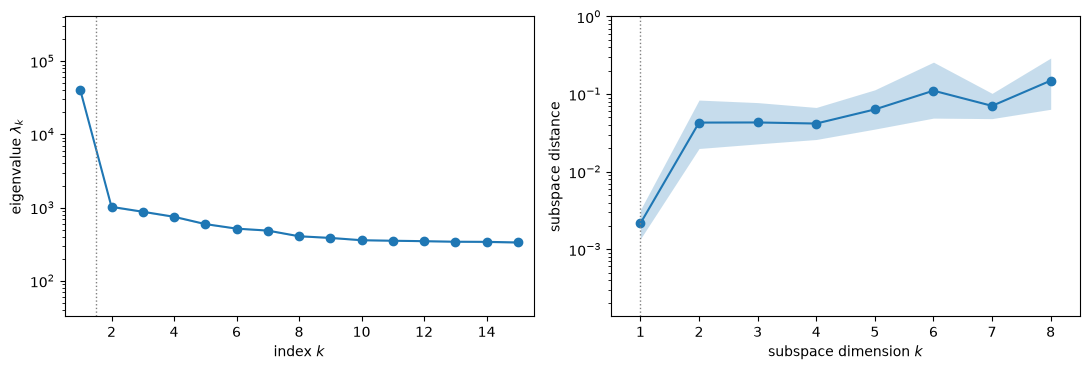

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ac.plotting.plot_eigenvalues(sub, interval='percentile', ax=ax[0])
ac.plotting.plot_subspace_errors(sub, k_max=8, ax=ax[1])
fig.tight_layout()
plt.close(fig)
fig

Left: eigenvalues with 95 % bootstrap intervals (percentile). Right: bootstrap subspace distances.
The first eigenvalue is 40537.7 (95 % interval [40346.2, 40750.0]) and the second 1022.4, a ratio of 39.65;
the next ratios are 1.17, 1.17, 1.26, 1.15 and 1.06. These later eigenvalues are not a clean picture of the
EUI: the fit variance of the local fits accounts for most of their sum (5813 of 7103), and $\lambda_2$ is almost
all fit variance (1005.3 of 1022.4 along $w_2$), while $\lambda_3 = 876.2$ and $\lambda_4 = 748.4$ exceed
theirs (362.8 and 384.3). The bootstrap intervals and subspace distances (median 0.002 for $n = 1$,
0.039–0.041 for $n = 2$–4) resample the fitted slopes without refitting them, so they understate the
uncertainty of everything after $\lambda_1$. Beyond $w_1$ there is a smaller smooth structure: the local
linear $w_3$ and $w_4$ (next cell), which with $w_1$ span nearly the same space as the global quadratic's
three leading directions, whose spectrum has its second gap after $\lambda_3$ (6.75; 8.26 for the library
QPHD). **Chosen dimension: $n = 1$**, from the ratio $\lambda_1/\lambda_2 = 39.65$ and the size of what the
further directions add: a cubic in $w_1$ and $w_3$ raises the leave-one-out $R^2$ from 0.8286 to 0.8567, and
a cubic in $w_1$, $w_3$ and $w_4$ to 0.8658 (below). The default gap rule of the library also gives $n = 1$.
The structure in $w_3$ and $w_4$ is real but secondary; a reader who wants it should use the three directions
$w_1$, $w_3$, $w_4$, not the first three.

w1: HVAC_efficiency -0.807, DHW_use +0.422, air_change_rate +0.255, equipment_density +0.207, heating_setpoint +0.186, occupancy -0.108, U_window +0.101
w2 (largest entries): U_floor -0.997, equipment_density +0.068, HVAC_efficiency +0.020
w3 (largest entries): equipment_density +0.559, HVAC_efficiency +0.548, DHW_use +0.479, air_change_rate +0.283, lighting_density +0.186
w4 (largest entries): U_wall -0.991, equipment_density +0.112, air_change_rate +0.047


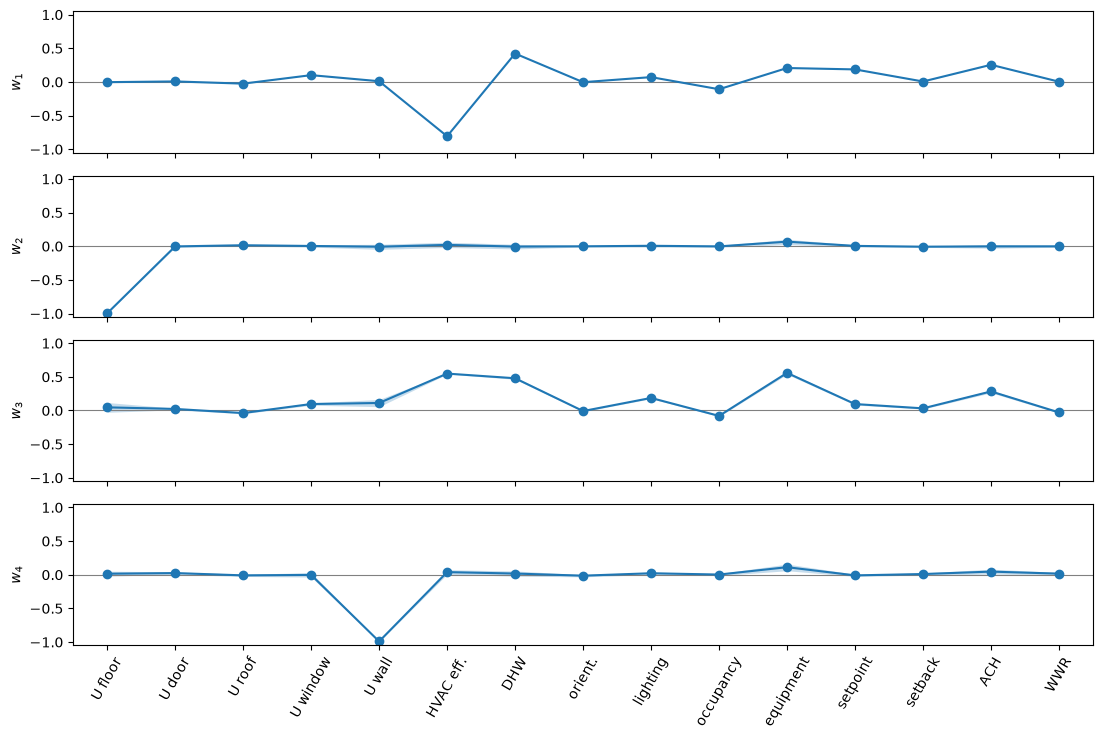

In [12]:
short = ['U floor', 'U door', 'U roof', 'U window', 'U wall', 'HVAC eff.', 'DHW', 'orient.', 'lighting',
         'occupancy', 'equipment', 'setpoint', 'setback', 'ACH', 'WWR']
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1, 2, 3], labels=short, interval='percentile',
                                         figsize=(11, 7.5))
for a in axs:
    a.tick_params(axis='x', labelrotation=60)
fig.tight_layout()
order = np.argsort(-np.abs(W[:, 0]))
print('w1:', ', '.join(f'{names[k]} {W[k, 0]:+.3f}' for k in order[:7]))
for k, top in ((1, 3), (2, 5), (3, 3)):
    print(f'w{k + 1} (largest entries):', ', '.join(f'{names[i]} {W[i, k]:+.3f}'
                                                  for i in np.argsort(-np.abs(W[:, k]))[:top]))
plt.close(fig)
fig

From the top: $w_1$ to $w_4$ (the bootstrap bands, from the resampled slopes, are narrower than the markers).
$w_1$ is led by the HVAC efficiency (−0.807) and the hot-water use (+0.422), then the air change rate (+0.255),
the equipment density (+0.207), the heating setpoint (+0.186), the occupancy (−0.108) and the window U-value
(+0.101); the other eight entries are smaller still. The signs follow the formula: the EUI rises as $\eta$
falls (through $c_H \propto 1/\eta$), and more hot water, ventilation, equipment electricity and a higher
setpoint add energy; the negative occupancy entry is consistent with occupants' internal gains reducing the
heating (an interpretation). The door, roof, wall and floor U-values, the orientation, the setback and the
window-to-wall ratio hardly enter $w_1$. $w_2$ is the floor U-value alone (−0.997), the direction of the
largest fit variance (above), and is read as estimator noise. $w_3$ combines the equipment density (+0.559),
the HVAC efficiency (+0.548), the hot-water use (+0.479) and the air change rate (+0.283), and $w_4$ is the
wall U-value (−0.991), the input with the most non-monotone level means of the space heating.

boiler rows 11939, heat-pump rows 37359; corr(w1^T x, EUI): boilers 0.745, heat pumps 0.921, all 0.899
residual of the cubic in w1^T x: sd 52.0 kWh/(m2 yr); corr(residual, w3^T x) over all rows 0.013, corr(residual, w2^T x) -0.001
corr(residual, w3^T x) within bins of w1^T x: [-2.5, -1) 0.764, [-1, -0.5) 0.586, [-0.5, 0) 0.235, [0, 0.5) -0.247, [0.5, 2) -0.340
mean w3^T x: boilers -0.78, heat pumps 0.08


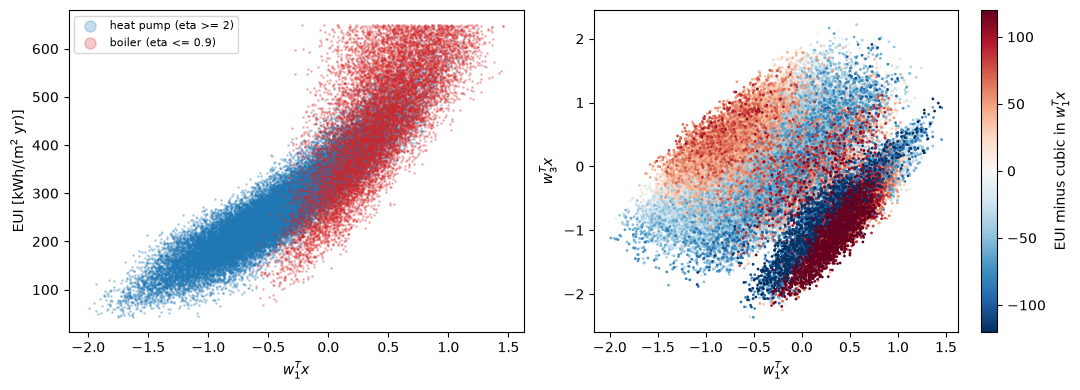

In [13]:
y = Xn @ W[:, :4]
boiler = eta < 1
s1 = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, 1), kind='poly', degree=3)
resid = f - ac.predict(s1, X)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y[~boiler, 0], f[~boiler], s=1, alpha=0.25, color='tab:blue', label='heat pump (eta >= 2)')
ax[0].scatter(y[boiler, 0], f[boiler], s=1, alpha=0.25, color='tab:red', label='boiler (eta <= 0.9)')
ax[0].set_xlabel('$w_1^T x$'); ax[0].set_ylabel('EUI [kWh/(m$^2$ yr)]')
ax[0].legend(markerscale=8, fontsize=8)
o = np.argsort(np.abs(resid))
sc = ax[1].scatter(y[o, 0], y[o, 2], c=resid[o], s=1, cmap='RdBu_r', vmin=-120, vmax=120)
ax[1].set_xlabel('$w_1^T x$'); ax[1].set_ylabel('$w_3^T x$')
fig.colorbar(sc, ax=ax[1], label='EUI minus cubic in $w_1^T x$')
fig.tight_layout()
r_boil = np.corrcoef(y[boiler, 0], f[boiler])[0, 1]
r_hp = np.corrcoef(y[~boiler, 0], f[~boiler])[0, 1]
print(f'boiler rows {boiler.sum()}, heat-pump rows {(~boiler).sum()}; corr(w1^T x, EUI): '
      f'boilers {r_boil:.3f}, heat pumps {r_hp:.3f}, all {np.corrcoef(y[:, 0], f)[0, 1]:.3f}')
print(f'residual of the cubic in w1^T x: sd {resid.std():.1f} kWh/(m2 yr); corr(residual, w3^T x) over all rows '
      f'{np.corrcoef(resid, y[:, 2])[0, 1]:.3f}, corr(residual, w2^T x) {np.corrcoef(resid, y[:, 1])[0, 1]:.3f}')
bins = [-2.5, -1.0, -0.5, 0.0, 0.5, 2.0]
print('corr(residual, w3^T x) within bins of w1^T x:', ', '.join(
    f'[{lo:g}, {hi:g}) {np.corrcoef(resid[(y[:, 0] >= lo) & (y[:, 0] < hi)], y[(y[:, 0] >= lo) & (y[:, 0] < hi), 2])[0, 1]:.3f}'
    for lo, hi in zip(bins[:-1], bins[1:])))
print(f'mean w3^T x: boilers {y[boiler, 2].mean():.2f}, heat pumps {y[~boiler, 2].mean():.2f}')
plt.close(fig)
fig

Left: the EUI against $w_1^\top\mathbf{x}$, coloured by heating system. Right: the rows in the plane of
$w_1^\top\mathbf{x}$ and $w_3^\top\mathbf{x}$, coloured by the residual of the cubic in $w_1^\top\mathbf{x}$ (colour scale clipped at both ends).
The left panel has two branches: the 11939 boiler rows ($\eta \le 0.9$, where $p_H = 1.1$) and the 37359
heat-pump rows ($\eta \ge 2$, $p_H = 2.08$), with correlations 0.745 and 0.921 between $w_1^\top\mathbf{x}$
and the EUI (0.899 over all rows). The boiler branch is steeper and runs into the cutoff at 650. In the right
panel the two branches lie apart along $w_3^\top\mathbf{x}$ (mean −0.78 for the boilers, 0.08 for the heat
pumps), and the residual (sd 52.0 kWh/(m² yr)) is organised in the plane: its correlation with
$w_3^\top\mathbf{x}$ is 0.013 over all rows but ranges from 0.764 ($w_1^\top\mathbf{x} < -1$) to −0.340
($w_1^\top\mathbf{x} \ge 0.5$) within bins of $w_1^\top\mathbf{x}$. So $w_3$ acts through its interaction with
$w_1$ (in particular the different slopes of the two branches), which a polynomial in both variables can
follow. The residual's correlation with $w_2^\top\mathbf{x}$ is −0.001.

In [14]:
def loo_r2_cubic(Yact):
    """Leave-one-out R^2 of the least-squares cubic in the columns of Yact (hat-matrix formula)."""
    k = Yact.shape[1]
    cols = [np.ones(M)] + [np.prod(Yact[:, list(c)], axis=1) for d in (1, 2, 3)
                           for c in itertools.combinations_with_replacement(range(k), d)]
    Qb, _ = np.linalg.qr(np.column_stack(cols))
    h = np.einsum('ij,ij->i', Qb, Qb)
    r = f - Qb @ (Qb.T @ f)
    return 1.0 - np.mean((r / (1.0 - h)) ** 2) / np.var(f)


rows = [('active variables w1, cubic', s1.loo_r_squared)]
for n in (2, 3):
    s_n = ac.with_dimension(sub, n)
    rows.append((f'active variables w1-w{n}, cubic', ac.fit_surrogate(X=X, f=f, subspace=s_n, kind='poly',
                                                                      degree=3).loo_r_squared))
rows.append(('active variables w1, cubic (formula)', loo_r2_cubic(y[:, [0]])))
rows.append(('active variables w1, w3, cubic', loo_r2_cubic(y[:, [0, 2]])))
rows.append(('active variables w1, w3, w4, cubic', loo_r2_cubic(y[:, [0, 2, 3]])))
rows.append(('all 15 inputs, degree 1', ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly',
                                                         degree=1).loo_r_squared))
rows.append(('all 15 inputs, degree 2', quad.loo_r_squared))
rows.append(('all 15 inputs, degree 3', ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly',
                                                         degree=3).loo_r_squared))
for label, r2 in rows:
    print(f'{label:38s} LOO R^2 = {r2:.4f}')

active variables w1, cubic             LOO R^2 = 0.8286
active variables w1-w2, cubic          LOO R^2 = 0.8293
active variables w1-w3, cubic          LOO R^2 = 0.8569
active variables w1, cubic (formula)   LOO R^2 = 0.8286
active variables w1, w3, cubic         LOO R^2 = 0.8567
active variables w1, w3, w4, cubic     LOO R^2 = 0.8658
all 15 inputs, degree 1                LOO R^2 = 0.8091
all 15 inputs, degree 2                LOO R^2 = 0.8664
all 15 inputs, degree 3                LOO R^2 = 0.8781


Leave-one-out $R^2$ of polynomial fits (directions held fixed). A cubic in the one active variable reaches
0.8286 (the hat-matrix formula used for the pairs below gives the same, 0.8286). Adding $w_2$ gives 0.8293,
a gain of less than 0.001, as expected of a noise direction; adding $w_3$ instead gives 0.8567, and $w_3$ and
$w_4$ together 0.8658, close to the 0.8664 of a quadratic in all 15 inputs (the first three directions give
0.8569). A cubic in all 15 inputs reaches 0.8781 and a linear fit 0.8091. Every smooth fit tried leaves at
least 12 % of the variance unexplained, which the template jumps and the cutoff of the previous sections
account for at least in part.

### Secondary output: annual space heating

The space heating is the simulated output through which the envelope, ventilation and schedule inputs act.
It is analysed with the global quadratic averaged over the rows and with OLS (the local linear estimate is not
repeated, to keep the run short); the library QPHD is printed as a check, and the signs follow the same
covariance rule.

In [15]:
ols_sh = ac.active_subspace(X=X, f=SH, space=space, estimator='ols', n=1)
quad_sh = ac.fit_surrogate(X=X, f=SH, space=space, subspace=None, kind='poly', degree=2)
q_sh = ac.active_subspace(grads=ac.predict_gradient(quad_sh, X), space=space, n=2)
q_sh = ac.orient(q_sh, by='covariance', X=X, f=SH, columns=2)
qphd_sh = ac.active_subspace(X=X, f=SH, space=space, estimator='qphd', n=2)
ls, lb_sh = q_sh.eigenvalues, qphd_sh.eigenvalues
print('quadratic over the rows: eigenvalues 1-5 (kWh/yr)^2', [f'{v:.3g}' for v in ls[:5]],
      ' ratios', (ls[:4] / ls[1:5]).round(2))
for k in (0, 1):
    print(f'w{k + 1}:', ', '.join(f'{names[i]} {q_sh.W[i, k]:+.3f}' for i in np.argsort(-np.abs(q_sh.W[:, k]))[:5]))
print(f'HVAC_efficiency entry of w1: {q_sh.W[names.index("HVAC_efficiency"), 0]:+.3f}')
print(f'|w1 . w1(OLS)| = {abs(q_sh.W[:, 0] @ ols_sh.W1[:, 0]):.4f}')
print(f'library QPHD (uniform box): ratios {(lb_sh[:4] / lb_sh[1:5]).round(2)}, |w1 . w1(QPHD)| = '
      f'{abs(q_sh.W[:, 0] @ qphd_sh.W[:, 0]):.4f}, |w2 . w2(QPHD)| = {abs(q_sh.W[:, 1] @ qphd_sh.W[:, 1]):.4f}')
for n in (1, 2):
    r2 = ac.fit_surrogate(X=X, f=SH, subspace=ac.with_dimension(q_sh, n), kind='poly', degree=3).loo_r_squared
    print(f'space heating, n = {n}, cubic: LOO R^2 = {r2:.4f}')
print(f'space heating, all 15 inputs, quadratic: LOO R^2 = {quad_sh.loo_r_squared:.4f}')

quadratic over the rows: eigenvalues 1-5 (kWh/yr)^2 ['8.24e+07', '2.03e+07', '9.23e+05', '6e+05', '4.06e+05']  ratios [ 4.07 21.94  1.54  1.48]
w1: air_change_rate +0.700, heating_setpoint +0.531, occupancy -0.305, U_window +0.274, equipment_density -0.187
w2: U_wall -0.993, heating_setpoint +0.069, air_change_rate +0.061, HVAC_efficiency +0.054, U_window +0.030
HVAC_efficiency entry of w1: +0.042
|w1 . w1(OLS)| = 0.9992
library QPHD (uniform box): ratios [ 5.46 18.98  2.07  1.53], |w1 . w1(QPHD)| = 0.9982, |w2 . w2(QPHD)| = 0.9996
space heating, n = 1, cubic: LOO R^2 = 0.6927
space heating, n = 2, cubic: LOO R^2 = 0.7310
space heating, all 15 inputs, quadratic: LOO R^2 = 0.7244


The space heating has a two-dimensional structure: the eigenvalues of the quadratic averaged over the rows
fall by ratios 4.07 and then 21.94. $w_1$ is led by the air change rate (+0.700) and the heating setpoint
(+0.531), with the occupancy (−0.305), the window U-value (+0.274) and the equipment density (−0.187); OLS
finds the same direction ($|w_1^\top w_1'|$ = 0.9992). $w_2$ is the wall U-value alone (−0.993), whose
non-monotone level means the quadratic fit can partly follow. The library QPHD gives the ratios 5.46 and
18.98 and the same two directions ($|\cos|$ 0.9982 and 0.9996). A cubic in $w_1^\top\mathbf{x}$ has
leave-one-out $R^2$ 0.6927, a cubic in two active variables 0.7310, and a quadratic in all 15 inputs 0.7244.
The HVAC efficiency has the small entry +0.042 in $w_1$ of the space heating; among the heat-pump rows the
space heating does not depend on $\eta$ (section on the cutoff below), so the entry is a trace of the cutoff,
which removed the low-$\eta$ runs with high space heating. $\eta$ acts on the EUI after the simulation, through
$c_H$. In the EUI the space heating is weighted by $p_H c_H$ and added to the water heating and the
electricity; the wall U-value, which leads $w_2$ here, has only a small entry in the EUI's $w_1$ and forms the
EUI's $w_4$.

### Scaling check

The analysis maps each input linearly from its Table 4 range, although the levels are not evenly spaced in
that range. The next cell maps each input instead through its empirical CDF (mid-ranks of the levels, scaled
to $[-1, 1]$), repeats the OLS fit and compares the weight vectors and one-variable cubic fits.

In [16]:
Xc = np.empty_like(X)
for j in range(m):
    lev, inv, c = np.unique(X[:, j], return_inverse=True, return_counts=True)
    Xc[:, j] = 2.0 * ((np.cumsum(c) - 0.5 * c) / M)[inv.ravel()] - 1.0   # mid-rank empirical CDF on [-1, 1]
space_c = ac.Uniform(-np.ones(m), np.ones(m), names=names)
ols_c = ac.active_subspace(X=Xc, f=f, space=space_c, estimator='ols', n=1)
print('OLS w1, Table 4 bounds :', ols.W1[:, 0].round(3))
print('OLS w1, empirical CDF  :', ols_c.W1[:, 0].round(3))
print(f'|cosine| between the two weight vectors: {abs(ols.W1[:, 0] @ ols_c.W1[:, 0]):.4f}')
for lab, Z, sp_, s_ in [('Table 4 bounds', X, space, ols), ('empirical CDF', Xc, space_c, ols_c)]:
    r2 = ac.fit_surrogate(X=Z, f=f, space=sp_, subspace=s_, kind='poly', degree=3).loo_r_squared
    print(f'{lab}: cubic in the OLS variable, LOO R^2 = {r2:.4f}')

OLS w1, Table 4 bounds : [ 0.002  0.006 -0.024  0.098  0.025 -0.815  0.405 -0.005  0.076 -0.105  0.221  0.18   0.01   0.25   0.005]
OLS w1, empirical CDF  : [ 0.002  0.005 -0.023  0.092  0.02  -0.757  0.486 -0.006  0.087 -0.114  0.253  0.195  0.011  0.242  0.006]
|cosine| between the two weight vectors: 0.9942


Table 4 bounds: cubic in the OLS variable, LOO R^2 = 0.8287
empirical CDF: cubic in the OLS variable, LOO R^2 = 0.8067


The two OLS directions agree ($|\cos|$ = 0.9942); the empirical-CDF scaling moves weight from the HVAC
efficiency (−0.815 to −0.757) to the hot-water use (0.405 to 0.486). A cubic in the OLS variable has
leave-one-out $R^2$ 0.8287 with the Table 4 scaling and 0.8067 with the empirical CDF, so the linear scaling
used above is the better one for this output, and the direction is not an artefact of it.

### What the cutoff does to the subspace

The runs with EUI ≥ 650 cannot be recovered, but a version of the cell without the cutoff can be built from
the stored columns and the EUI identity alone. Among the heat-pump rows the EUI seldom comes near 650 (rows
with EUI ≥ 600 are counted below), the space heating does not depend on $\eta$ (its regression slope on $\eta$,
with the other inputs held, is printed), and the heating usage, the electricity and the floor area do not
depend on $\eta$ at all. So each heat-pump row is repeated three times with $\eta$ redrawn uniformly from its
20 levels (seed `SEED`), and the EUI is recomputed from the identity. If this rebuilt cell, cut at 650,
reproduces the missing fraction and the thinning of the low-$\eta$ levels, the cutoff explains them, and the
subspaces with and without it can be compared. The comparison uses OLS and the global quadratic averaged over
the rows (local linear fits on the 112,077 rebuilt rows would take too long here).

In [17]:
# A version of this cell without the cutoff, built from the stored columns and the EUI identity alone:
# the heat-pump rows, each repeated 3 times with HVAC_efficiency redrawn from its 20 levels
hp = eta >= 2
lev_eta = np.unique(eta)
print('rows with EUI >= 600 per heat-pump level:', ', '.join(f'{v:g}: {np.sum((eta == v) & (f >= 600))}'
                                                          for v in lev_eta[(lev_eta >= 2) & (lev_eta <= 3)]),
      '; none above 3')
Zh = np.c_[np.ones(hp.sum()), X[hp]]
c_h, *_ = np.linalg.lstsq(Zh, SH[hp], rcond=None)
r_h = SH[hp] - Zh @ c_h
se_h = np.sqrt(r_h.var(ddof=Zh.shape[1]) * np.linalg.inv(Zh.T @ Zh)[6, 6])
print(f'heat-pump rows: slope of space heating on HVAC_efficiency, other inputs held: {c_h[6]:.1f} '
      f'(standard error {se_h:.1f}) kWh/yr per unit')


def eui_identity(e, Q, E, area):
    """EUI from the identity of the model section."""
    return (np.where(e < 1, 1.1, 2.08) * np.round(1.084 / e, 3) * Q + 2.08 * E) / area


rng = np.random.default_rng(SEED)
Xu = np.repeat(X[hp], 3, axis=0)
Xu[:, 5] = rng.choice(lev_eta, size=Xu.shape[0])
fu = eui_identity(Xu[:, 5], np.repeat(out['heating_usage'][hp], 3), np.repeat(out['electricity_energy'][hp], 3),
                  np.repeat(A[hp], 3))
SHu = np.repeat(SH[hp], 3)
kept = fu < 650
print(f'counterfactual rows {fu.size}; fraction with EUI >= 650: {1 - kept.mean():.3f} (cell: {1 - M / expected:.3f})')
print('kept fraction per level, counterfactual / cell (rows over the heat-pump mean):')
print('  ' + ', '.join(f'{v:g}: {kept[Xu[:, 5] == v].mean():.3f}/{c / hp_mean:.3f}' for v, c in zip(lev_eta[:9], cnt[:9])))
print('mean space heating of the kept rows at eta = 0.3, 0.6, 0.9 (kWh/yr): counterfactual',
      [round(SHu[kept & (Xu[:, 5] == v)].mean()) for v in (0.3, 0.6, 0.9)],
      ' cell', [round(SH[eta == v].mean()) for v in (0.3, 0.6, 0.9)])
res_cf = {}
for lab, Xs, fs in [('without cutoff', Xu, fu), ('with cutoff', Xu[kept], fu[kept]), ('cell', X, f)]:
    o1 = ac.active_subspace(X=Xs, f=fs, space=space, estimator='ols', n=1)
    qs = ac.fit_surrogate(X=Xs, f=fs, space=space, subspace=None, kind='poly', degree=2)
    q1 = ac.active_subspace(grads=ac.predict_gradient(qs, Xs), space=space, n=1)
    res_cf[lab] = (o1.W1[:, 0], q1.W[:, 0], q1.eigenvalues)
    u = o1.W1[:, 0] * np.sign(o1.W1[6, 0])
    print(f'{lab:15s} OLS w1: HVAC_efficiency {u[5]:+.3f}, DHW_use {u[6]:+.3f}, equipment_density {u[10]:+.3f}; '
          f'quadratic over the rows: lambda_1 {q1.eigenvalues[0]:.0f}, ratios '
          f'{(q1.eigenvalues[:3] / q1.eigenvalues[1:4]).round(2)}')
for a, b_ in [('without cutoff', 'with cutoff'), ('with cutoff', 'cell')]:
    print(f'{a} vs. {b_}: |cos| of OLS w1 {abs(res_cf[a][0] @ res_cf[b_][0]):.4f}, of quadratic w1 '
          f'{abs(res_cf[a][1] @ res_cf[b_][1]):.4f}; lambda_1 ratio {res_cf[a][2][0] / res_cf[b_][2][0]:.2f}')

rows with EUI >= 600 per heat-pump level: 2: 51, 2.2: 21, 2.4: 4, 2.6: 0, 2.8: 1, 3: 0 ; none above 3
heat-pump rows: slope of space heating on HVAC_efficiency, other inputs held: 6.7 (standard error 28.9) kWh/yr per unit
counterfactual rows 112077; fraction with EUI >= 650: 0.141 (cell: 0.142)
kept fraction per level, counterfactual / cell (rows over the heat-pump mean):
  0.3: 0.166/0.163, 0.4: 0.299/0.298, 0.5: 0.474/0.461, 0.6: 0.638/0.621, 0.7: 0.784/0.769, 0.8: 0.886/0.891, 0.9: 0.955/0.952, 2: 0.991/0.992, 2.2: 0.997/1.020
mean space heating of the kept rows at eta = 0.3, 0.6, 0.9 (kWh/yr): counterfactual [6205, 9800, 12127]  cell [6234, 9872, 11924]


without cutoff  OLS w1: HVAC_efficiency -0.859, DHW_use +0.373, equipment_density +0.123; quadratic over the rows: lambda_1 203995, ratios [37.78  1.72  8.46]


with cutoff     OLS w1: HVAC_efficiency -0.818, DHW_use +0.403, equipment_density +0.220; quadratic over the rows: lambda_1 44644, ratios [27.89  1.16  6.9 ]


cell            OLS w1: HVAC_efficiency -0.815, DHW_use +0.405, equipment_density +0.221; quadratic over the rows: lambda_1 44107, ratios [28.05  1.13  6.75]
without cutoff vs. with cutoff: |cos| of OLS w1 0.9934, of quadratic w1 0.9780; lambda_1 ratio 4.57
with cutoff vs. cell: |cos| of OLS w1 1.0000, of quadratic w1 0.9999; lambda_1 ratio 1.01


Among the heat-pump rows, 51 have an EUI ≥ 600 at $\eta = 2$, 21 at 2.2 and almost none above, and the slope
of the space heating on $\eta$ is 6.7 kWh/yr per unit with standard error 28.9: the heat-pump rows are nearly
untouched by the cutoff and carry no $\eta$ effect on the space heating (the few already removed at
$\eta$ = 2 and 2.2 are missing from the rebuilt cell too). Cut at 650, the rebuilt cell loses a fraction 0.141
of its rows (the stored cell: 0.142), keeps 0.166, 0.474 and 0.886 of the rows at $\eta$ = 0.3, 0.5 and 0.8
(the stored cell: 0.163, 0.461 and 0.891), and its kept rows have mean space heating 6205, 9800 and 12127
kWh/yr at $\eta$ = 0.3, 0.6 and 0.9 (stored: 6234, 9872 and 11924). The cutoff thus explains the missing rows,
the thinning of the low-$\eta$ levels and the space-heating trend over the boiler levels: the runs at or above
650 were removed after the simulations. Without the cutoff the OLS direction gives more weight to the HVAC
efficiency (−0.859 against −0.818) and less to the equipment density (+0.123 against +0.220), with $|\cos|$
0.9934 between the two; the quadratic's $w_1$ moves by $|\cos|$ 0.9780, and its leading eigenvalue is 4.57
times larger (203995 against 44644), with $\lambda_1/\lambda_2$ = 37.78 against 27.89. The rebuilt cell with
the cutoff matches the stored cell ($|\cos|$ 1.0000 for OLS and 0.9999 for the quadratic). The cutoff turns
$w_1$ only a little, but it removes the steepest part of the EUI, at low HVAC efficiency, and with it most of
the size of the leading eigenvalue: everything in this notebook describes the EUI on the set where it is below
650.

## Comparison with the paper

The paper reports no active subspace; its analysis of the inputs is the correlation of each with the EUI over
the whole deposited table (Fig. 1, p. 6; text p. 5), which mixes the four building types, both weather files
and both renewables options. The cell below sets those correlations beside the ones in this cell.

In [18]:
fig1 = {'U_floor': 0.24, 'U_door': 0.31, 'U_roof': 0.33, 'U_window': 0.35, 'U_wall': 0.33,
        'HVAC_efficiency': -0.68, 'DHW_use': 0.45, 'orientation': 0.35, 'lighting_density': 0.24,
        'occupancy': -0.058, 'equipment_density': 0.36, 'heating_setpoint': 0.35, 'heating_setback': 0.19,
        'air_change_rate': 0.43, 'window_to_wall_ratio': 0.00085}   # Fig. 1, p. 6 (all 1,030,022 rows)
print(f'{"input":22s} {"Fig. 1 (all rows)":>18s} {"this subset":>12s}')
for j, n in enumerate(names):
    print(f'{n:22s} {fig1[n]:18.5g} {np.corrcoef(X[:, j], f)[0, 1]:12.3f}')
print(f'EUI mean {f.mean():.2f}, sd {f.std(ddof=1):.2f}, max {f.max():.2f} kWh/(m2 yr) (this subset)')

input                   Fig. 1 (all rows)  this subset
U_floor                              0.24        0.001
U_door                               0.31        0.001
U_roof                               0.33       -0.012
U_window                             0.35        0.071
U_wall                               0.33        0.008
HVAC_efficiency                     -0.68       -0.650
DHW_use                              0.45        0.355
orientation                          0.35       -0.006
lighting_density                     0.24        0.085
occupancy                          -0.058       -0.086
equipment_density                    0.36        0.223
heating_setpoint                     0.35        0.144
heating_setback                      0.19       -0.000
air_change_rate                      0.43        0.185
window_to_wall_ratio              0.00085        0.001
EUI mean 315.91, sd 125.51, max 649.97 kWh/(m2 yr) (this subset)


| quantity | paper (all rows) | this notebook (one cell) |
|---|---|---|
| active subspace | not reported | $n = 1$, $\lambda_1/\lambda_2$ = 39.65 (local linear); $w_3$, $w_4$ raise the LOO $R^2$ from 0.8286 to 0.8658 |
| leading input | HVAC efficiency, "the most significant correlation" (p. 5) | HVAC efficiency, −0.807 in $w_1$ |
| corr(HVAC efficiency, EUI) | −0.68 (Fig. 1, p. 6) | −0.650 |
| corr(DHW use, EUI) | 0.45 (Fig. 1) | 0.355 |
| corr(air change rate, EUI) | 0.43 (Fig. 1) | 0.185 |
| corr(equipment density, EUI) | 0.36 (Fig. 1; 0.35 in the text, p. 5) | 0.223 |
| corr(heating setpoint, EUI) | 0.35 (Fig. 1) | 0.144 |
| corr(U-values, EUI) | 0.24–0.35 (Fig. 1; text p. 5) | −0.012 to 0.071 |
| corr(orientation, EUI) | 0.35 (Fig. 1) | −0.006 |
| corr(lighting density, EUI) | 0.24 (Fig. 1) | 0.085 |
| corr(heating setback, EUI) | 0.19 (Fig. 1) | below 0.0005 in magnitude |
| corr(occupancy, EUI) | −0.058 (Fig. 1; −0.06 in the text) | −0.086 |
| corr(window-to-wall ratio, EUI) | 0.00085 (Fig. 1; 0.00 in the text) | 0.001 |
| EUI mean, sd, max (kWh/(m² yr)) | 241.38, 148, 650 (Table 3, p. 5) | 315.91, 125.51, 649.97 |
| EUI cutoff at 650 | not mentioned | no run at or above 650; a fraction 0.142 of the cell's runs missing (0.141 in the cell rebuilt without the cutoff, whose leading eigenvalue is 4.57 times larger) |
| variance left by smooth fits | not reported | LOO $R^2$ 0.8286 (one variable), 0.8781 (cubic in all 15) |

The ordering agrees at the top (HVAC efficiency, then hot water), but within one cell the U-values and the
orientation, at 0.24–0.35 in Fig. 1, are nearly uncorrelated with the EUI. Their correlations in the paper
come from the mixing of cells and from correlations between the inputs over the whole table, which the
deposited data show (see DATA.md); they do not measure the effect of the U-values within a building type.
The mean EUI of this cell is higher than that of the whole table; the cell has no photovoltaics, which
lower the EUI of the rows that have them (an expectation, not checked here).

## References

- U. Ali, S. Bano, M. H. Shamsi, D. Sood, C. Hoare, W. Zuo, N. Hewitt, J. O'Donnell. Urban residential
  building stock synthetic datasets for building energy performance analysis. *Data in Brief* 53:110241,
  2024. [doi:10.1016/j.dib.2024.110241](https://doi.org/10.1016/j.dib.2024.110241).
  Data: U. Ali, S. Bano, J. O'Donnell, Urban Building Energy Stock Datasets, Mendeley Data, version 1,
  [doi:10.17632/m6vv9k9gcd.1](https://doi.org/10.17632/m6vv9k9gcd.1).
- U. Ali, S. Bano, M. H. Shamsi, D. Sood, C. Hoare, W. Zuo, N. Hewitt, J. O'Donnell. Urban building energy
  performance prediction and retrofit analysis using data-driven machine learning approach. *Energy and
  Buildings* 303:113768, 2024.
  [doi:10.1016/j.enbuild.2023.113768](https://doi.org/10.1016/j.enbuild.2023.113768).
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## Acknowledgments

From the paper (p. 10): "This publication has emanated from the US-Ireland R&D Partnership supported by the
Science Foundation Ireland through 20/US/3695, the U.S. National Science Foundation through Award Number
2217410, and the Department for the Economy in Northern Ireland through USI 167. We would also acknowledge
NexSys project supported by the Science Foundation Ireland through Award Number SFI/21/SPP/3756." The data
are the authors' (Mendeley Data, CC BY 4.0); this notebook only analyses them.

In [19]:
print(f'notebook run time: {time.time() - T_START:.0f} s')

notebook run time: 319 s
